<a href="https://colab.research.google.com/github/denizbutengineer/bart-capacity-planner/blob/main/btk_final_proje.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Ortam Kurulumu ve Ham Veri Yükleme
Gerekli kütüphaneleri kurar ve BART'ın 2025 yılına ait saatlik Başlangıç-Varış (Origin-Destination) ham yolcu verisini sıkıştırılmış .zip arşivinden bellek dostu veri tipleriyle okur.

In [1]:
!pip install -q lightgbm xgboost catboost holidays networkx joblib

import os
import gc
import glob
import json
import time
import warnings
from pathlib import Path

import holidays
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb

from catboost import CatBoostRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Colab sol panelindeki Dosyalar bölümüne date-hour-soo-dest-2025.csv.zip
# dosyasını yükleyin.
zip_files = glob.glob("*2025*.zip")
csv_files = glob.glob("*2025*.csv")

if zip_files:
    FILE_PATH = zip_files[0]
    COMPRESSION = "zip"
elif csv_files:
    FILE_PATH = csv_files[0]
    COMPRESSION = None
else:
    raise FileNotFoundError(
        "date-hour-soo-dest-2025.csv.zip veya 2025 yılına ait CSV dosyası bulunamadı. "
        "Dosyayı Colab çalışma alanına yükleyin."
    )

print(f"Okunan dosya: {FILE_PATH}")
print(f"Sıkıştırma: {COMPRESSION}")

cols = ["Date", "Hour", "Origin", "Destination", "Trips"]

df_raw = pd.read_csv(
    FILE_PATH,
    compression=COMPRESSION,
    header=None,
    names=cols,
    dtype={
        "Hour": "int8",
        "Origin": "category",
        "Destination": "category",
        "Trips": "int32"
    }
)

df_raw["Date"] = pd.to_datetime(df_raw["Date"], errors="coerce")

print(f"Yüklenen toplam satır: {len(df_raw):,}")
display(df_raw.head())


## 1.2 Ham veri kalite özeti

print("VERİ BOYUTU:", df_raw.shape)

print("\nVERİ TİPLERİ:")
display(df_raw.dtypes.to_frame("dtype"))

print("\nEKSİK DEĞERLER:")
display(df_raw.isna().sum().to_frame("missing_count"))

print("\nTAM SATIR DUPLICATE SAYISI:")
print(int(df_raw.duplicated().sum()))

print("\nO-D ANAHTARI DUPLICATE SAYISI:")
od_key = ["Date", "Hour", "Origin", "Destination"]
print(int(df_raw.duplicated(subset=od_key).sum()))

print("\nGEÇERSİZ SAAT SAYISI:")
print(int((~df_raw["Hour"].between(0, 23)).sum()))

print("\nNEGATİF TRIPS SAYISI:")
print(int((df_raw["Trips"] < 0).sum()))

print("\nTARİH ARALIĞI:")
print(df_raw["Date"].min(), "-", df_raw["Date"].max())

print("\nTRIPS TANIMLAYICI İSTATİSTİKLERİ:")
display(df_raw["Trips"].describe().to_frame())

print("\nORIGIN / DESTINATION KATEGORİ SAYILARI:")
print("Origin:", df_raw["Origin"].nunique())
print("Destination:", df_raw["Destination"].nunique())

# Geçersiz anahtar alanları veya negatif Trips bulunan satırlar modelleme
# zincirine alınmaz. Duplicate satırlar otomatik silinmez; sayıları raporlanır.
invalid_mask = (
    df_raw["Date"].isna()
    | ~df_raw["Hour"].between(0, 23)
    | df_raw["Origin"].isna()
    | df_raw["Destination"].isna()
    | (df_raw["Trips"] < 0)
)

invalid_count = int(invalid_mask.sum())
print(f"\nGeçersiz alan nedeniyle çıkarılacak satır: {invalid_count:,}")

if invalid_count > 0:
    df_raw = df_raw.loc[~invalid_mask].copy()

print("Temizlenmiş ham veri boyutu:", df_raw.shape)

Okunan dosya: date-hour-soo-dest-2025.zip
Sıkıştırma: zip
Yüklenen toplam satır: 9,143,257


,Date,Hour,Origin,Destination,Trips
0,2025-01-01,0,12TH,16TH,1
1,2025-01-01,0,12TH,ANTC,1
2,2025-01-01,0,12TH,BALB,1
3,2025-01-01,0,12TH,BERY,1
4,2025-01-01,0,12TH,CIVC,8


VERİ BOYUTU: (9143257, 5)

VERİ TİPLERİ:


,dtype
Date,datetime64[ns]
Hour,int8
Origin,category
Destination,category
Trips,int32



EKSİK DEĞERLER:


,missing_count
Date,0
Hour,0
Origin,0
Destination,0
Trips,0



TAM SATIR DUPLICATE SAYISI:
0

O-D ANAHTARI DUPLICATE SAYISI:
0

GEÇERSİZ SAAT SAYISI:
0

NEGATİF TRIPS SAYISI:
0

TARİH ARALIĞI:
2025-01-01 00:00:00 - 2025-12-31 00:00:00

TRIPS TANIMLAYICI İSTATİSTİKLERİ:


,Trips
count,9.143257e+06
mean,5.961481e+00
std,1.206927e+01
min,1.000000e+00
25%,1.000000e+00
50%,2.000000e+00
75%,6.000000e+00
max,9.440000e+02



ORIGIN / DESTINATION KATEGORİ SAYILARI:
Origin: 50
Destination: 50

Geçersiz alan nedeniyle çıkarılacak satır: 0
Temizlenmiş ham veri boyutu: (9143257, 5)


# 2. Ağ Yönlendirme ve Hat Maksimum Kesit Yükü Hesaplama
İstasyon ağını graf olarak modeller, ortak koridorlardaki yolcu akışını o kesiti paylaşan hat sayısına böler ve her tarih, saat, hat ve yön için en kalabalık kesitteki yolcu yükünü (Max_Segment_Load) hesaplar

In [2]:
import gc

LINES = {
    "Red": [
        "RICH", "DELN", "PLZA", "NBRK", "DBRK", "ASHB", "MCAR", "19TH",
        "12TH", "WOAK", "EMBR", "MONT", "POWL", "CIVC", "16TH", "24TH",
        "GLEN", "BALB", "DALY", "COLM", "SSAN", "SBRN", "SFIA", "MLBR"
    ],
    "Orange": [
        "RICH", "DELN", "PLZA", "NBRK", "DBRK", "ASHB", "MCAR", "19TH",
        "12TH", "LAKE", "FTVL", "COLS", "SANL", "BAYF", "HAYW", "SHAY",
        "UCTY", "FRMT", "WARM", "MLPT", "BERY"
    ],
    "Yellow": [
        "ANTC", "PCTR", "PITT", "NCON", "CONC", "PHIL", "WCRK", "LAFY",
        "ORIN", "ROCK", "MCAR", "19TH", "12TH", "WOAK", "EMBR", "MONT",
        "POWL", "CIVC", "16TH", "24TH", "GLEN", "BALB", "DALY", "COLM",
        "SSAN", "SBRN", "SFIA"
    ],
    "Blue": [
        "DUBL", "WDUB", "CAST", "BAYF", "SANL", "COLS", "FTVL", "LAKE",
        "WOAK", "EMBR", "MONT", "POWL", "CIVC", "16TH", "24TH", "GLEN",
        "BALB", "DALY"
    ],
    "Green": [
        "BERY", "MLPT", "WARM", "FRMT", "UCTY", "SHAY", "HAYW", "BAYF",
        "SANL", "COLS", "FTVL", "LAKE", "WOAK", "EMBR", "MONT", "POWL",
        "CIVC", "16TH", "24TH", "GLEN", "BALB", "DALY"
    ]
}

G = nx.DiGraph()
edge_to_lines = {}

# Her hat için gidiş ve dönüş yönlü kenarlarını oluştur.
for line_name, stations in LINES.items():
    for i in range(len(stations) - 1):
        u, v = stations[i], stations[i + 1]
        G.add_edge(u, v)
        edge_to_lines.setdefault((u, v), []).append((line_name, 0))

    reverse_stations = stations[::-1]
    for i in range(len(reverse_stations) - 1):
        u, v = reverse_stations[i], reverse_stations[i + 1]
        G.add_edge(u, v)
        edge_to_lines.setdefault((u, v), []).append((line_name, 1))

# Her yönlü kenara benzersiz Edge_ID ata.
edge_list = sorted(edge_to_lines.keys())
edge_to_id = {edge: idx for idx, edge in enumerate(edge_list)}

valid_stations = set(G.nodes())

# Ağda bulunmayan istasyonları ve aynı istasyonda başlayıp biten kayıtları çıkar.
od_pairs = df_raw[["Origin", "Destination"]].drop_duplicates()
od_pairs = od_pairs[
    od_pairs["Origin"].isin(valid_stations)
    & od_pairs["Destination"].isin(valid_stations)
    & (od_pairs["Origin"] != od_pairs["Destination"])
].copy()

print("Graf düğüm sayısı:", G.number_of_nodes())
print("Graf yönlü kenar sayısı:", G.number_of_edges())
print("Geçerli benzersiz O-D çifti:", len(od_pairs))

# Her O-D çiftinin en kısa yolu üzerindeki Edge_ID değerlerini çıkar.
od_edge_rows = []
no_path_count = 0

for row in od_pairs.itertuples(index=False):
    try:
        path = nx.shortest_path(G, row.Origin, row.Destination)
        for i in range(len(path) - 1):
            edge_id = edge_to_id[(path[i], path[i + 1])]
            od_edge_rows.append((row.Origin, row.Destination, edge_id))
    except nx.NetworkXNoPath:
        no_path_count += 1
        continue

print("Yol bulunamayan O-D çiftleri:", no_path_count)

df_od_edges = pd.DataFrame(
    od_edge_rows,
    columns=["Origin", "Destination", "Edge_ID"]
)

df_od_edges["Origin"] = df_od_edges["Origin"].astype(df_raw["Origin"].dtype)
df_od_edges["Destination"] = df_od_edges["Destination"].astype(df_raw["Destination"].dtype)
df_od_edges["Edge_ID"] = df_od_edges["Edge_ID"].astype("int16")

print("O-D / Edge eşleşmesi:", df_od_edges.shape)

# RAM kullanımını azaltmak için ham veriyi ay bazında birleştir ve topla.
df_raw["Month_Tmp"] = df_raw["Date"].dt.month.astype("int8")
edge_load_chunks = []

for month in range(1, 13):
    sub = df_raw.loc[
        df_raw["Month_Tmp"] == month,
        ["Date", "Hour", "Origin", "Destination", "Trips"]
    ]

    if sub.empty:
        continue

    merged = sub.merge(
        df_od_edges,
        on=["Origin", "Destination"],
        how="inner"
    )

    agg = (
        merged.groupby(["Date", "Hour", "Edge_ID"], as_index=False)["Trips"]
        .sum()
    )

    edge_load_chunks.append(agg)

    del sub, merged, agg
    gc.collect()

if not edge_load_chunks:
    raise RuntimeError("O-D kayıtlarından kesit yükü üretilemedi.")

df_raw.drop(columns=["Month_Tmp"], inplace=True)
df_edge_totals = pd.concat(edge_load_chunks, ignore_index=True)
del edge_load_chunks
gc.collect()

# Her Edge_ID'nin hangi hat/yön tarafından paylaşıldığını eşleştir.
edge_line_map = []

for edge, serving_lines in edge_to_lines.items():
    edge_id = edge_to_id[edge]
    share = 1.0 / len(serving_lines)

    for line_name, direction in serving_lines:
        edge_line_map.append((edge_id, line_name, direction, share))

df_edge_line = pd.DataFrame(
    edge_line_map,
    columns=["Edge_ID", "Line", "Direction", "Share"]
)
df_edge_line["Edge_ID"] = df_edge_line["Edge_ID"].astype("int16")

# Paylaşılan kenar yükünü o kenarı kullanan hatlara eşit dağıt.
df_line_loads = df_edge_totals.merge(
    df_edge_line,
    on="Edge_ID",
    how="inner"
)

df_line_loads["Edge_Load"] = (
    df_line_loads["Trips"] * df_line_loads["Share"]
).astype("float32")

hourly_max = (
    df_line_loads
    .groupby(["Date", "Hour", "Line", "Direction"], as_index=False)["Edge_Load"]
    .max()
    .rename(columns={"Edge_Load": "Hourly_Max_Load"})
)

print(
    "Saatlik maksimum kesit yükü tablosu oluşturuldu:",
    f"{len(hourly_max):,} satır"
)

display(hourly_max.head())

print("\nSaatlik tabloda eksik yük:", int(hourly_max["Hourly_Max_Load"].isna().sum()))
print("Saatlik tabloda negatif yük:", int((hourly_max["Hourly_Max_Load"] < 0).sum()))
print(
    "Aynı tarih-saat-hat-yön anahtarında duplicate:",
    int(hourly_max.duplicated(["Date", "Hour", "Line", "Direction"]).sum())
)
print("Hat dağılımı:")
display(hourly_max["Line"].value_counts().to_frame("row_count"))

Graf düğüm sayısı: 49
Graf yönlü kenar sayısı: 98
Geçerli benzersiz O-D çifti: 2352
Yol bulunamayan O-D çiftleri: 0
O-D / Edge eşleşmesi: (25214, 3)
Saatlik maksimum kesit yükü tablosu oluşturuldu: 81,325 satır


,Date,Hour,Line,Direction,Hourly_Max_Load
0,2025-01-01,0,Blue,0,161.25
1,2025-01-01,0,Blue,1,229.75
2,2025-01-01,0,Green,0,161.25
3,2025-01-01,0,Green,1,229.75
4,2025-01-01,0,Orange,0,78.00



Saatlik tabloda eksik yük: 0
Saatlik tabloda negatif yük: 0
Aynı tarih-saat-hat-yön anahtarında duplicate: 0
Hat dağılımı:


,row_count
Line,
Red,16302
Blue,16264
Green,16263
Orange,16248
Yellow,16248


# 3. Keşifçi Veri Analizi (EDA) ve Veri Kalitesi Kontrolü
Sefer dışı boş saatleri takvim ızgarasıyla tamamlar, tekrarlayan kayıt (duplicate) kontrolü yapar ve hedef değişkenin hat ve saat bazlı dağılımını görselleştirir.

Tam zaman ızgarası satır sayısı: 87600
Sıfırla doldurulan saat-hat-yön kombinasyonu: 6275
10 dakikalık tablo boyutu: (525600, 9)
Hedef eksik değer: 0
Hedef negatif değer: 0
Tam satır duplicate: 0

Hedef değişken istatistikleri:


,Max_Segment_Load
count,525600.000000
mean,81.532600
std,97.842758
min,0.000000
25%,18.916666
50%,55.319443
75%,100.416664
max,789.833313


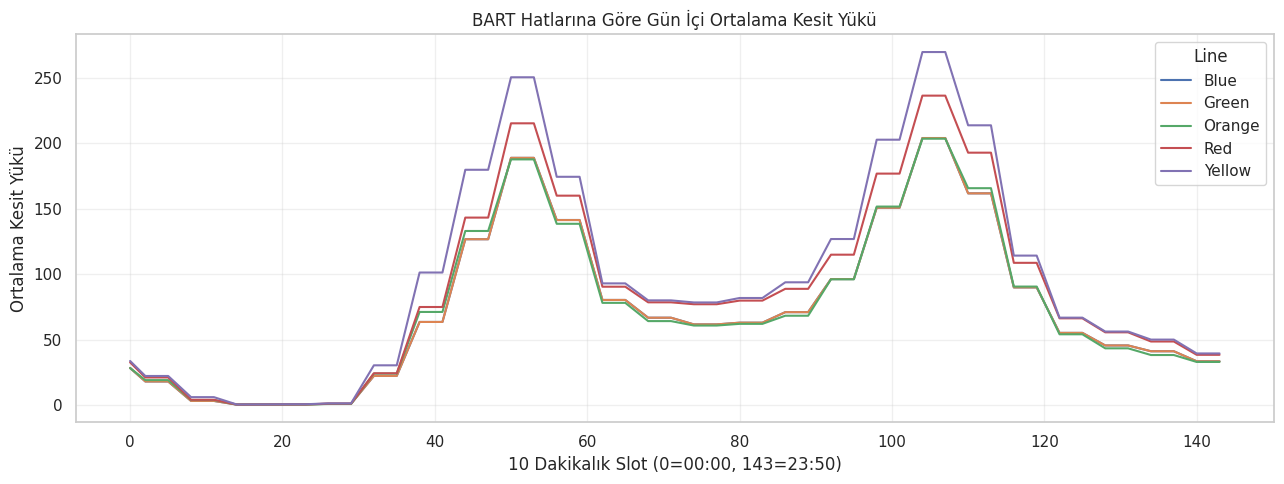

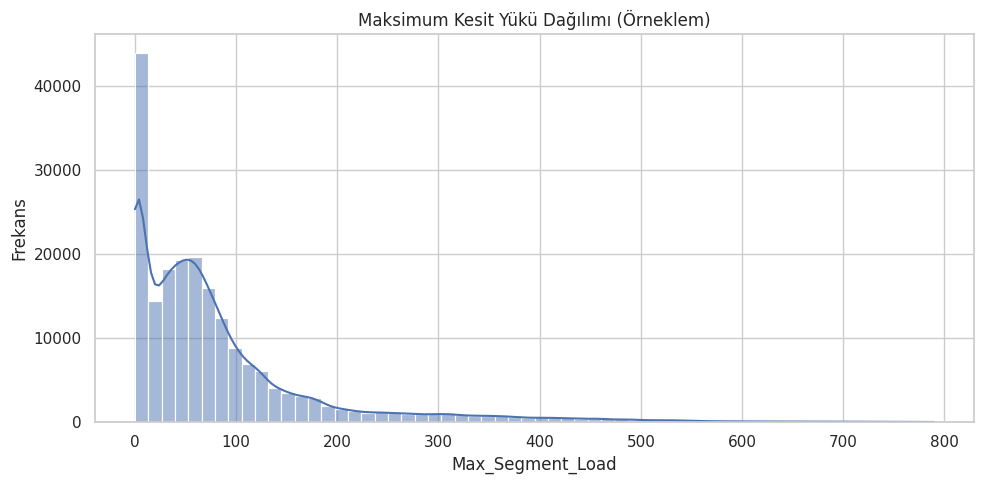

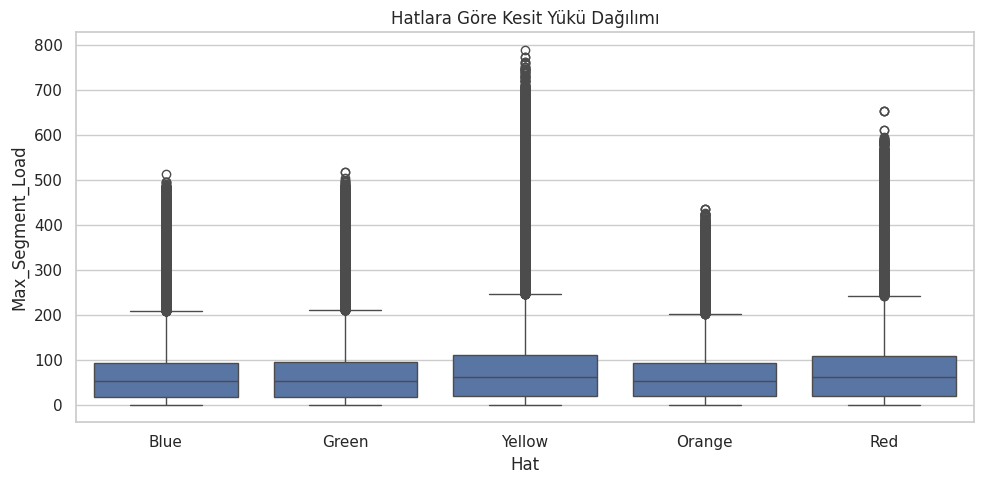

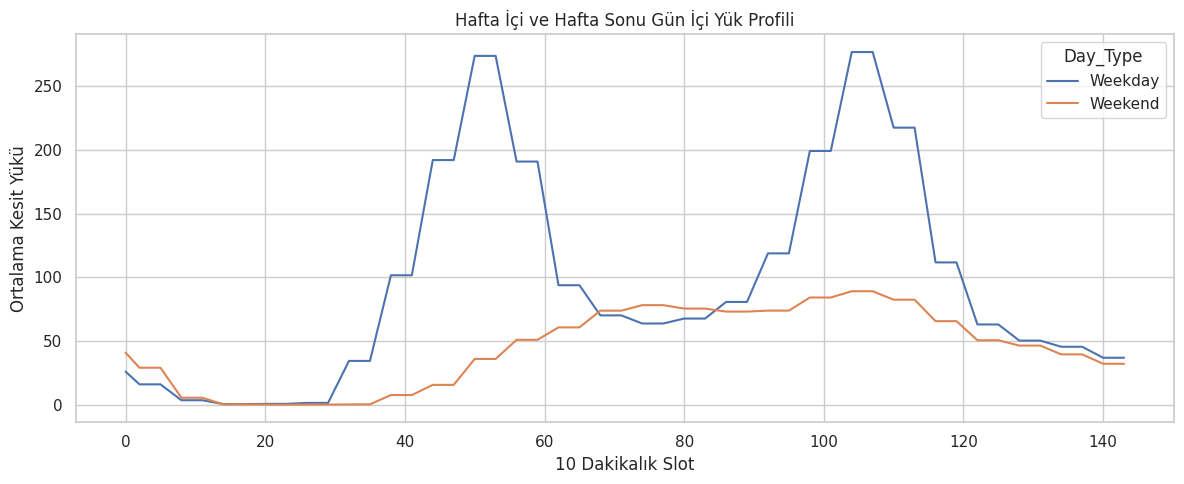

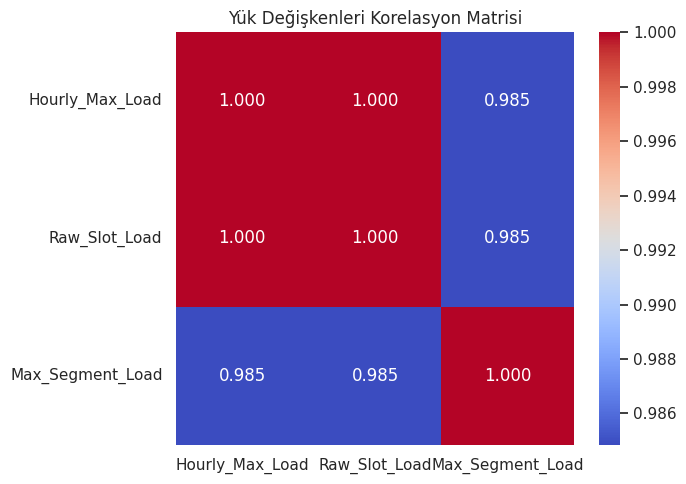

,Kontrol,Adet
0,Hourly_Max_Load eksik,0
1,Max_Segment_Load eksik,0
2,Max_Segment_Load negatif,0
3,df_full duplicate satır,0
4,hourly_max duplicate anahtar,0


In [3]:
# Gün, saat, hat ve yön için tam zaman ızgarası oluştur.
all_dates = pd.date_range(
    hourly_max["Date"].min(),
    hourly_max["Date"].max(),
    freq="D"
)

expected_index = pd.MultiIndex.from_product(
    [all_dates, range(24), list(LINES.keys()), [0, 1]],
    names=["Date", "Hour", "Line", "Direction"]
)

grid = expected_index.to_frame(index=False)

df_hourly = grid.merge(
    hourly_max,
    on=["Date", "Hour", "Line", "Direction"],
    how="left",
    validate="one_to_one"
)

missing_hourly_before_fill = int(df_hourly["Hourly_Max_Load"].isna().sum())
df_hourly["Hourly_Max_Load"] = df_hourly["Hourly_Max_Load"].fillna(0.0).astype("float32")

print("Tam zaman ızgarası satır sayısı:", len(df_hourly))
print("Sıfırla doldurulan saat-hat-yön kombinasyonu:", missing_hourly_before_fill)

# Her saati altı adet 10 dakikalık slota ayır.
slots = pd.DataFrame({"Sub_Slot": range(6)})
df_full = df_hourly.merge(slots, how="cross")

df_full["Slot_Of_Day"] = (
    df_full["Hour"] * 6 + df_full["Sub_Slot"]
).astype("int16")

df_full["Raw_Slot_Load"] = (
    df_full["Hourly_Max_Load"] / 6.0
).astype("float32")

df_full = df_full.sort_values(
    ["Line", "Direction", "Date", "Slot_Of_Day"]
).reset_index(drop=True)

# Hedef: mevcut slot ve önceki iki slotun geriye dönük hareketli ortalaması.
df_full["Max_Segment_Load"] = (
    df_full.groupby(["Line", "Direction"])["Raw_Slot_Load"]
    .transform(
        lambda s: s.rolling(
            window=3,
            min_periods=1,
            center=False
        ).mean()
    )
    .astype("float32")
)

print("10 dakikalık tablo boyutu:", df_full.shape)
print("Hedef eksik değer:", int(df_full["Max_Segment_Load"].isna().sum()))
print("Hedef negatif değer:", int((df_full["Max_Segment_Load"] < 0).sum()))
print("Tam satır duplicate:", int(df_full.duplicated().sum()))
print("\nHedef değişken istatistikleri:")
display(df_full["Max_Segment_Load"].describe().to_frame())

# 3.1 Hat bazında gün içi ortalama kesit yükü
profile_line = (
    df_full.groupby(["Line", "Slot_Of_Day"], as_index=False)["Max_Segment_Load"]
    .mean()
)

plt.figure(figsize=(13, 5))
sns.lineplot(
    data=profile_line,
    x="Slot_Of_Day",
    y="Max_Segment_Load",
    hue="Line"
)
plt.title("BART Hatlarına Göre Gün İçi Ortalama Kesit Yükü")
plt.xlabel("10 Dakikalık Slot (0=00:00, 143=23:50)")
plt.ylabel("Ortalama Kesit Yükü")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3.2 Hedef değişken dağılımı — büyük tabloda bellek için örneklem kullan.
plot_sample = df_full[
    "Max_Segment_Load"
].sample(
    n=min(200_000, len(df_full)),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(10, 5))
sns.histplot(plot_sample, bins=60, kde=True)
plt.title("Maksimum Kesit Yükü Dağılımı (Örneklem)")
plt.xlabel("Max_Segment_Load")
plt.ylabel("Frekans")
plt.tight_layout()
plt.show()

# 3.3 Hat bazında yük dağılımı
box_sample = df_full.sample(
    n=min(150_000, len(df_full)),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=box_sample,
    x="Line",
    y="Max_Segment_Load"
)
plt.title("Hatlara Göre Kesit Yükü Dağılımı")
plt.xlabel("Hat")
plt.ylabel("Max_Segment_Load")
plt.tight_layout()
plt.show()

# 3.4 Hafta içi / hafta sonu talep profili
weekday_profile = df_full.copy()
weekday_profile["Day_Type"] = np.where(
    weekday_profile["Date"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

weekday_profile = (
    weekday_profile.groupby(["Day_Type", "Slot_Of_Day"], as_index=False)["Max_Segment_Load"]
    .mean()
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=weekday_profile,
    x="Slot_Of_Day",
    y="Max_Segment_Load",
    hue="Day_Type"
)
plt.title("Hafta İçi ve Hafta Sonu Gün İçi Yük Profili")
plt.xlabel("10 Dakikalık Slot")
plt.ylabel("Ortalama Kesit Yükü")
plt.tight_layout()
plt.show()

# 3.5 Saatlik yük ile türetilmiş slot hedefinin ilişkisi
corr_sample = df_full[
    ["Hourly_Max_Load", "Raw_Slot_Load", "Max_Segment_Load"]
].sample(
    n=min(100_000, len(df_full)),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_sample.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".3f"
)
plt.title("Yük Değişkenleri Korelasyon Matrisi")
plt.tight_layout()
plt.show()

# 3.6 Kalite kontrol özet tablosu
quality_summary = pd.DataFrame({
    "Kontrol": [
        "Hourly_Max_Load eksik",
        "Max_Segment_Load eksik",
        "Max_Segment_Load negatif",
        "df_full duplicate satır",
        "hourly_max duplicate anahtar"
    ],
    "Adet": [
        int(df_hourly["Hourly_Max_Load"].isna().sum()),
        int(df_full["Max_Segment_Load"].isna().sum()),
        int((df_full["Max_Segment_Load"] < 0).sum()),
        int(df_full.duplicated().sum()),
        int(hourly_max.duplicated(["Date", "Hour", "Line", "Direction"]).sum())
    ]
})
display(quality_summary)

# 4. Özellik Mühendisliği ve Zamansal Veri Bölünmesi
Hat isimleri sayısal Line_Code değerlerine eşlenir; takvim, Kaliforniya resmi tatilleri, döngüsel zaman (sin/cos), sabah/akşam pik saat göstergeleri ve geçmişe dönük gecikme (Lag_1d, Lag_7d, Rolling_Mean_7d) özellikleri üretilir. Veri seti kronolojik olarak Ocak–Eylül (Train), Ekim–Kasım (Validation) ve Aralık (Test) şeklinde ayrılır.

In [4]:
# Hat kodlaması
line_mapping = {
    "Blue": 0,
    "Green": 1,
    "Orange": 2,
    "Red": 3,
    "Yellow": 4
}

df_full["Line_Code"] = df_full["Line"].map(line_mapping).astype("int8")

# Takvim özellikleri
df_full["Day_Of_Week"] = df_full["Date"].dt.dayofweek.astype("int8")
df_full["Is_Weekend"] = (df_full["Day_Of_Week"] >= 5).astype("int8")
df_full["Month"] = df_full["Date"].dt.month.astype("int8")
df_full["Day_Of_Year"] = df_full["Date"].dt.dayofyear.astype("int16")

# Kaliforniya resmi tatilleri — Date ile datetime.date tiplerini eşleştir.
us_ca_holidays = holidays.US(subdiv="CA", years=[2025])
holiday_dates = set(us_ca_holidays.keys())
df_full["Is_Holiday"] = (
    df_full["Date"].dt.date.isin(holiday_dates)
).astype("int8")

# Döngüsel zaman özellikleri
df_full["Slot_Sin"] = np.sin(
    2 * np.pi * df_full["Slot_Of_Day"] / 144.0
).astype("float32")

df_full["Slot_Cos"] = np.cos(
    2 * np.pi * df_full["Slot_Of_Day"] / 144.0
).astype("float32")

df_full["Dow_Sin"] = np.sin(
    2 * np.pi * df_full["Day_Of_Week"] / 7.0
).astype("float32")

df_full["Dow_Cos"] = np.cos(
    2 * np.pi * df_full["Day_Of_Week"] / 7.0
).astype("float32")

# İş günü ve pik saat göstergeleri
is_workday = (
    (df_full["Is_Weekend"] == 0)
    & (df_full["Is_Holiday"] == 0)
)

df_full["Is_AM_Peak"] = (
    is_workday & df_full["Slot_Of_Day"].between(42, 57)
).astype("int8")

df_full["Is_PM_Peak"] = (
    is_workday & df_full["Slot_Of_Day"].between(99, 114)
).astype("int8")

# Aynı hat-yön ve aynı gün içi slotu için tarih sırasını kur.
df_full = df_full.sort_values(
    ["Line_Code", "Direction", "Slot_Of_Day", "Date"]
).reset_index(drop=True)

slot_group = df_full.groupby(
    ["Line_Code", "Direction", "Slot_Of_Day"],
    sort=False
)["Max_Segment_Load"]

# Aynı 10 dakikalık slotun 1 ve 7 gün önceki hedef değerleri.
df_full["Lag_1d"] = slot_group.shift(1).astype("float32")
df_full["Lag_7d"] = slot_group.shift(7).astype("float32")

# Önceki yedi günün aynı slotundaki ortalama.
df_full["Rolling_Mean_7d"] = slot_group.transform(
    lambda s: s.shift(1).rolling(
        window=7,
        min_periods=7
    ).mean()
).astype("float32")

feature_cols = [
    "Line_Code", "Direction", "Slot_Of_Day",
    "Day_Of_Week", "Is_Weekend", "Month", "Day_Of_Year", "Is_Holiday",
    "Slot_Sin", "Slot_Cos", "Dow_Sin", "Dow_Cos",
    "Is_AM_Peak", "Is_PM_Peak",
    "Lag_1d", "Lag_7d", "Rolling_Mean_7d"
]

# Üç lag girdisi de hazır olmayan ilk yedi günlük satırları modelleme dışında bırak.
df_model = df_full.dropna(
    subset=["Lag_1d", "Lag_7d", "Rolling_Mean_7d"]
).copy()

df_model["Target_Log"] = np.log1p(
    df_model["Max_Segment_Load"].clip(lower=0)
).astype("float32")

# Kronolojik ayrım: Ocak-Eylül train, Ekim-Kasım validation, Aralık test.
train_df = df_model[df_model["Month"] <= 9].copy()
val_df = df_model[df_model["Month"].isin([10, 11])].copy()
test_df = df_model[df_model["Month"] == 12].copy()

X_train = train_df[feature_cols].copy()
y_train_log = train_df["Target_Log"].copy()

X_val = val_df[feature_cols].copy()
y_val_log = val_df["Target_Log"].copy()

X_test = test_df[feature_cols].copy()
y_test_log = test_df["Target_Log"].copy()

y_val_real = val_df["Max_Segment_Load"].to_numpy(dtype=np.float32)
y_test_real = test_df["Max_Segment_Load"].to_numpy(dtype=np.float32)

print(f"Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
print("Özellik sayısı:", len(feature_cols))
print("Özelliklerde eksik değer:", int(df_model[feature_cols].isna().sum().sum()))
print("Train tarih aralığı:", train_df["Date"].min(), "-", train_df["Date"].max())
print("Validation tarih aralığı:", val_df["Date"].min(), "-", val_df["Date"].max())
print("Test tarih aralığı:", test_df["Date"].min(), "-", test_df["Date"].max())

display(df_model[feature_cols + ["Max_Segment_Load", "Target_Log"]].head())

Train: 383,040 | Val: 87,840 | Test: 44,640
Özellik sayısı: 17
Özelliklerde eksik değer: 0
Train tarih aralığı: 2025-01-08 00:00:00 - 2025-09-30 00:00:00
Validation tarih aralığı: 2025-10-01 00:00:00 - 2025-11-30 00:00:00
Test tarih aralığı: 2025-12-01 00:00:00 - 2025-12-31 00:00:00


,Line_Code,Direction,Slot_Of_Day,Day_Of_Week,Is_Weekend,Month,Day_Of_Year,Is_Holiday,Slot_Sin,Slot_Cos,Dow_Sin,Dow_Cos,Is_AM_Peak,Is_PM_Peak,Lag_1d,Lag_7d,Rolling_Mean_7d,Max_Segment_Load,Target_Log
7,0,0,0,2,0,1,8,0,0.0,1.0,0.974928,-0.222521,0,0,10.092592,26.875000,11.798942,8.583333,2.260026
8,0,0,0,3,0,1,9,0,0.0,1.0,0.433884,-0.900969,0,0,8.583333,5.819445,9.185846,9.347222,2.336718
9,0,0,0,4,0,1,10,0,0.0,1.0,-0.433884,-0.900969,0,0,9.347222,11.361111,9.689815,9.625000,2.363210
10,0,0,0,5,1,1,11,0,0.0,1.0,-0.974928,-0.222521,0,0,9.625000,12.319445,9.441799,12.958333,2.636077
11,0,0,0,6,1,1,12,0,0.0,1.0,-0.781832,0.623490,0,0,12.958333,9.763889,9.533069,12.625000,2.611906


# 5. Model Eğitimi ve Karşılaştırması
Referans (Baseline) grup ortalaması ile Ridge Regression, LightGBM, XGBoost ve CatBoost modelleri log1p hedef değişkeni üzerinde eğitilir; tahminler expm1 ile gerçek yolcu sayısına geri dönüştürülerek Validation seti üzerinde RMSE, MAE ve
𝑅^2
  metrikleriyle karşılaştırılır.

In [5]:
def eval_metrics(y_true, y_pred, model_name):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_pred = np.clip(y_pred, 0, None)

    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))

    return {
        "Model": model_name,
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "R2": round(r2, 5)
    }

results = []
training_times = {}

# 5.1 Group Mean Baseline
baseline_map = (
    train_df.groupby(
        ["Line_Code", "Direction", "Slot_Of_Day", "Is_Weekend"]
    )["Max_Segment_Load"]
    .mean()
    .reset_index()
    .rename(columns={"Max_Segment_Load": "Baseline_Prediction"})
)

global_train_mean = float(train_df["Max_Segment_Load"].mean())

val_base = (
    val_df[
        ["Line_Code", "Direction", "Slot_Of_Day", "Is_Weekend"]
    ]
    .merge(
        baseline_map,
        on=["Line_Code", "Direction", "Slot_Of_Day", "Is_Weekend"],
        how="left",
        validate="many_to_one"
    )["Baseline_Prediction"]
    .fillna(global_train_mean)
    .to_numpy()
)

results.append(
    eval_metrics(y_val_real, val_base, "Baseline (Group Mean)")
)

# 5.2 Ridge Regression
start_time = time.perf_counter()
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train_log)
ridge_pred = np.clip(np.expm1(ridge.predict(X_val)), 0, None)
training_times["Ridge Regression"] = time.perf_counter() - start_time
results.append(eval_metrics(y_val_real, ridge_pred, "Ridge Regression"))

# 5.3 LightGBM — başlangıç parametreleri
start_time = time.perf_counter()
lgbm = lgb.LGBMRegressor(
    n_estimators=600,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)
lgbm.fit(X_train, y_train_log)
lgbm_pred = np.clip(np.expm1(lgbm.predict(X_val)), 0, None)
training_times["LightGBM"] = time.perf_counter() - start_time
results.append(eval_metrics(y_val_real, lgbm_pred, "LightGBM"))

# 5.4 XGBoost — başlangıç parametreleri
start_time = time.perf_counter()
xgbr = xgb.XGBRegressor(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
xgbr.fit(X_train, y_train_log)
xgb_pred = np.clip(np.expm1(xgbr.predict(X_val)), 0, None)
training_times["XGBoost"] = time.perf_counter() - start_time
results.append(eval_metrics(y_val_real, xgb_pred, "XGBoost"))

# 5.5 CatBoost — başlangıç parametreleri
start_time = time.perf_counter()
cbr = CatBoostRegressor(
    iterations=600,
    learning_rate=0.06,
    depth=8,
    loss_function="RMSE",
    random_seed=RANDOM_STATE,
    verbose=False,
    thread_count=-1
)
cbr.fit(X_train, y_train_log)
cat_pred = np.clip(np.expm1(cbr.predict(X_val)), 0, None)
training_times["CatBoost"] = time.perf_counter() - start_time
results.append(eval_metrics(y_val_real, cat_pred, "CatBoost"))

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

results_df["Training_Time_Seconds"] = results_df["Model"].map(training_times)
display(results_df)

results_df.to_csv("initial_model_comparison.csv", index=False)

,Model,RMSE,MAE,R2,Training_Time_Seconds
0,CatBoost,20.7311,9.5618,0.95322,39.313131
1,LightGBM,21.0656,9.9051,0.95170,25.012633
2,XGBoost,21.3911,10.2793,0.95020,22.176888
3,Baseline (Group Mean),34.9399,16.7994,0.86712,NaN
4,Ridge Regression,139.7370,39.0037,-1.12535,0.145737


# 6. XGBoot Hiperparametre Optimizasyonu

In [6]:
# XGBoost parametre araması yalnızca Train üzerinde öğrenir ve Validation üzerinde seçilir.
# Aralık Test seti bu bölümde kullanılmaz.

xgb_param_distributions = {
    "n_estimators": [300, 450, 600, 750],
    "max_depth": [4, 5, 6, 8],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "reg_lambda": [0.5, 1.0, 3.0, 5.0]
}

xgb_candidates = list(
    ParameterSampler(
        xgb_param_distributions,
        n_iter=12,
        random_state=RANDOM_STATE
    )
)

xgb_tuning_rows = []
best_xgb_rmse = float("inf")
best_xgb_params = None
best_xgb_model = None

for trial_number, params in enumerate(xgb_candidates, start=1):
    start_time = time.perf_counter()

    candidate_model = xgb.XGBRegressor(
        **params,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    candidate_model.fit(X_train, y_train_log)

    candidate_pred = np.clip(
        np.expm1(candidate_model.predict(X_val)),
        0,
        None
    )

    rmse = float(np.sqrt(mean_squared_error(y_val_real, candidate_pred)))
    mae = float(mean_absolute_error(y_val_real, candidate_pred))
    r2 = float(r2_score(y_val_real, candidate_pred))
    elapsed = time.perf_counter() - start_time

    xgb_tuning_rows.append({
        "Trial": trial_number,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Training_Time_Seconds": elapsed,
        "Parameters": params
    })

    print(
        f"Trial {trial_number}/{len(xgb_candidates)} | "
        f"RMSE={rmse:.4f} | MAE={mae:.4f} | R2={r2:.5f} | "
        f"Time={elapsed:.1f}s"
    )

    if rmse < best_xgb_rmse:
        best_xgb_rmse = rmse
        best_xgb_params = params.copy()
        best_xgb_model = candidate_model

xgb_tuning_df = (
    pd.DataFrame(xgb_tuning_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(xgb_tuning_df.drop(columns=["Parameters"]))
print("En iyi XGBoost parametreleri:")
print(best_xgb_params)

xgb_tuning_df.to_csv("xgboost_tuning_results.csv", index=False)

# Başlangıç XGBoost ve optimize XGBoost doğrulama karşılaştırması
xgb_before_metrics = eval_metrics(
    y_val_real,
    xgb_pred,
    "XGBoost Before Tuning"
)

xgb_after_pred = np.clip(
    np.expm1(best_xgb_model.predict(X_val)),
    0,
    None
)

xgb_after_metrics = eval_metrics(
    y_val_real,
    xgb_after_pred,
    "XGBoost After Tuning"
)

xgb_tuning_comparison = pd.DataFrame([
    xgb_before_metrics,
    xgb_after_metrics
])

display(xgb_tuning_comparison)
xgb_tuning_comparison.to_csv("xgboost_before_after_tuning.csv", index=False)

Trial 1/12 | RMSE=22.0235 | MAE=10.2200 | R2=0.94721 | Time=12.0s
Trial 2/12 | RMSE=22.0958 | MAE=10.5708 | R2=0.94686 | Time=14.8s
Trial 3/12 | RMSE=20.7508 | MAE=9.7104 | R2=0.95313 | Time=16.2s
Trial 4/12 | RMSE=22.0606 | MAE=10.2875 | R2=0.94703 | Time=8.2s
Trial 5/12 | RMSE=22.3735 | MAE=10.3466 | R2=0.94552 | Time=12.0s
Trial 6/12 | RMSE=22.4681 | MAE=10.5312 | R2=0.94505 | Time=5.0s
Trial 7/12 | RMSE=21.6875 | MAE=10.3898 | R2=0.94881 | Time=20.8s
Trial 8/12 | RMSE=21.6584 | MAE=10.0068 | R2=0.94894 | Time=8.2s
Trial 9/12 | RMSE=21.5449 | MAE=10.0435 | R2=0.94948 | Time=17.1s
Trial 10/12 | RMSE=21.8339 | MAE=10.0153 | R2=0.94811 | Time=23.7s
Trial 11/12 | RMSE=22.0175 | MAE=10.3114 | R2=0.94724 | Time=16.7s
Trial 12/12 | RMSE=22.4743 | MAE=10.3944 | R2=0.94502 | Time=7.7s


,Trial,RMSE,MAE,R2,Training_Time_Seconds
0,3,20.750838,9.710359,0.953132,16.220239
1,9,21.544935,10.043483,0.949476,17.099230
2,8,21.658390,10.006764,0.948942,8.164377
3,7,21.687456,10.389848,0.948805,20.842338
4,10,21.833853,10.015307,0.948112,23.690635
5,11,22.017545,10.311431,0.947235,16.710179
6,1,22.023528,10.220037,0.947206,11.991624
7,4,22.060583,10.287475,0.947029,8.204825
8,2,22.095834,10.570845,0.946859,14.762044
9,5,22.373463,10.346572,0.945515,12.047317


En iyi XGBoost parametreleri:
{'subsample': 0.7, 'reg_lambda': 5.0, 'n_estimators': 450, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.02, 'colsample_bytree': 0.7}


,Model,RMSE,MAE,R2
0,XGBoost Before Tuning,21.3911,10.2793,0.95020
1,XGBoost After Tuning,20.7508,9.7104,0.95313


In [7]:
# XGBoost, CatBoost ve LightGBM aynı Train / Validation ayrımında kıyaslanır.
# Buradaki aramalar da Test setini kullanmaz.

# 7.1 CatBoost parametre araması
cat_param_distributions = {
    "iterations": [300, 450, 600, 750],
    "depth": [5, 6, 8, 10],
    "learning_rate": [0.03, 0.05, 0.06, 0.08],
    "l2_leaf_reg": [3, 5, 7, 9]
}

cat_candidates = list(
    ParameterSampler(
        cat_param_distributions,
        n_iter=8,
        random_state=RANDOM_STATE
    )
)

cat_tuning_rows = []
best_cat_rmse = float("inf")
best_cat_params = None
best_cat_model = None

for trial_number, params in enumerate(cat_candidates, start=1):
    start_time = time.perf_counter()

    candidate_model = CatBoostRegressor(
        **params,
        loss_function="RMSE",
        random_seed=RANDOM_STATE,
        verbose=False,
        thread_count=-1
    )

    candidate_model.fit(X_train, y_train_log)
    candidate_pred = np.clip(
        np.expm1(candidate_model.predict(X_val)),
        0,
        None
    )

    rmse = float(np.sqrt(mean_squared_error(y_val_real, candidate_pred)))
    mae = float(mean_absolute_error(y_val_real, candidate_pred))
    r2 = float(r2_score(y_val_real, candidate_pred))
    elapsed = time.perf_counter() - start_time

    cat_tuning_rows.append({
        "Trial": trial_number,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Training_Time_Seconds": elapsed,
        "Parameters": params
    })

    print(
        f"CatBoost {trial_number}/{len(cat_candidates)} | "
        f"RMSE={rmse:.4f} | MAE={mae:.4f} | R2={r2:.5f}"
    )

    if rmse < best_cat_rmse:
        best_cat_rmse = rmse
        best_cat_params = params.copy()
        best_cat_model = candidate_model

cat_tuning_df = (
    pd.DataFrame(cat_tuning_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(cat_tuning_df.drop(columns=["Parameters"]))
print("En iyi CatBoost parametreleri:")
print(best_cat_params)
cat_tuning_df.to_csv("catboost_tuning_results.csv", index=False)

# 7.2 LightGBM parametre araması
lgb_param_distributions = {
    "n_estimators": [300, 450, 600, 750],
    "num_leaves": [31, 47, 63, 95],
    "max_depth": [-1, 6, 8, 10],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "reg_lambda": [0.5, 1.0, 3.0, 5.0]
}

lgb_candidates = list(
    ParameterSampler(
        lgb_param_distributions,
        n_iter=8,
        random_state=RANDOM_STATE
    )
)

lgb_tuning_rows = []
best_lgb_rmse = float("inf")
best_lgb_params = None
best_lgb_model = None

for trial_number, params in enumerate(lgb_candidates, start=1):
    start_time = time.perf_counter()

    candidate_model = lgb.LGBMRegressor(
        **params,
        objective="regression",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )

    candidate_model.fit(X_train, y_train_log)
    candidate_pred = np.clip(
        np.expm1(candidate_model.predict(X_val)),
        0,
        None
    )

    rmse = float(np.sqrt(mean_squared_error(y_val_real, candidate_pred)))
    mae = float(mean_absolute_error(y_val_real, candidate_pred))
    r2 = float(r2_score(y_val_real, candidate_pred))
    elapsed = time.perf_counter() - start_time

    lgb_tuning_rows.append({
        "Trial": trial_number,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Training_Time_Seconds": elapsed,
        "Parameters": params
    })

    print(
        f"LightGBM {trial_number}/{len(lgb_candidates)} | "
        f"RMSE={rmse:.4f} | MAE={mae:.4f} | R2={r2:.5f}"
    )

    if rmse < best_lgb_rmse:
        best_lgb_rmse = rmse
        best_lgb_params = params.copy()
        best_lgb_model = candidate_model

lgb_tuning_df = (
    pd.DataFrame(lgb_tuning_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(lgb_tuning_df.drop(columns=["Parameters"]))
print("En iyi LightGBM parametreleri:")
print(best_lgb_params)
lgb_tuning_df.to_csv("lightgbm_tuning_results.csv", index=False)

# 7.3 Optimize edilmiş üç güçlü modelin aynı validation setindeki karşılaştırması
competitor_results = []

for model_name, model_obj in [
    ("Optimized XGBoost", best_xgb_model),
    ("Optimized CatBoost", best_cat_model),
    ("Optimized LightGBM", best_lgb_model)
]:
    prediction = np.clip(
        np.expm1(model_obj.predict(X_val)),
        0,
        None
    )
    competitor_results.append(
        eval_metrics(y_val_real, prediction, model_name)
    )

competitor_results_df = (
    pd.DataFrame(competitor_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(competitor_results_df)
competitor_results_df.to_csv(
    "optimized_strong_competitor_comparison.csv",
    index=False
)

# Deployment için XGBoost final model olarak korunur:
# JSON formatında kaydedilip Streamlit tarafında XGBoost API'siyle yüklenir.
# Rakip modellerin sonuçları, XGBoost tercihinin performans/dağıtım dengesi
# açısından raporda gerekçelendirilmesi için saklanır.

CatBoost 1/8 | RMSE=20.5684 | MAE=9.4906 | R2=0.95395
CatBoost 2/8 | RMSE=22.3590 | MAE=10.3921 | R2=0.94559
CatBoost 3/8 | RMSE=21.4633 | MAE=9.8246 | R2=0.94986
CatBoost 4/8 | RMSE=20.7474 | MAE=9.5723 | R2=0.95315
CatBoost 5/8 | RMSE=21.4814 | MAE=9.7637 | R2=0.94977
CatBoost 6/8 | RMSE=20.8006 | MAE=9.5663 | R2=0.95291
CatBoost 7/8 | RMSE=20.5851 | MAE=9.5692 | R2=0.95388
CatBoost 8/8 | RMSE=21.3279 | MAE=9.8284 | R2=0.95049


,Trial,RMSE,MAE,R2,Training_Time_Seconds
0,1,20.568370,9.490624,0.953952,76.683313
1,7,20.585097,9.569224,0.953877,90.373854
2,4,20.747396,9.572274,0.953147,36.294152
3,6,20.800630,9.566280,0.952907,45.165291
4,8,21.327944,9.828354,0.950489,37.096834
5,3,21.463272,9.824555,0.949858,14.485448
6,5,21.481415,9.763720,0.949773,36.451989
7,2,22.359007,10.392114,0.945586,13.160272


En iyi CatBoost parametreleri:
{'learning_rate': 0.03, 'l2_leaf_reg': 5, 'iterations': 600, 'depth': 10}
LightGBM 1/8 | RMSE=20.9384 | MAE=9.8651 | R2=0.95228
LightGBM 2/8 | RMSE=21.4646 | MAE=9.9590 | R2=0.94985
LightGBM 3/8 | RMSE=21.7117 | MAE=10.0751 | R2=0.94869
LightGBM 4/8 | RMSE=22.0962 | MAE=10.2129 | R2=0.94686
LightGBM 5/8 | RMSE=21.2796 | MAE=9.6726 | R2=0.95071
LightGBM 6/8 | RMSE=21.5110 | MAE=9.9575 | R2=0.94963
LightGBM 7/8 | RMSE=21.1278 | MAE=10.0637 | R2=0.95141
LightGBM 8/8 | RMSE=20.9934 | MAE=9.8358 | R2=0.95203


,Trial,RMSE,MAE,R2,Training_Time_Seconds
0,1,20.938385,9.865101,0.952281,11.811004
1,8,20.993433,9.835776,0.952029,7.185592
2,7,21.127846,10.063696,0.951413,20.944759
3,5,21.279600,9.672583,0.950713,13.927298
4,2,21.464577,9.959000,0.949852,17.506136
5,6,21.511039,9.957538,0.949635,13.361295
6,3,21.711656,10.075090,0.948691,15.410334
7,4,22.096197,10.212884,0.946857,8.572641


En iyi LightGBM parametreleri:
{'subsample': 0.9, 'reg_lambda': 1.0, 'num_leaves': 63, 'n_estimators': 450, 'max_depth': -1, 'learning_rate': 0.08, 'colsample_bytree': 0.8}


,Model,RMSE,MAE,R2
0,Optimized CatBoost,20.5684,9.4906,0.95395
1,Optimized XGBoost,20.7508,9.7104,0.95313
2,Optimized LightGBM,20.9384,9.8651,0.95228


FINAL TEST METRİKLERİ


,Model,RMSE,MAE,R2
0,Final XGBoost (December Test),54.126,23.5776,0.56816


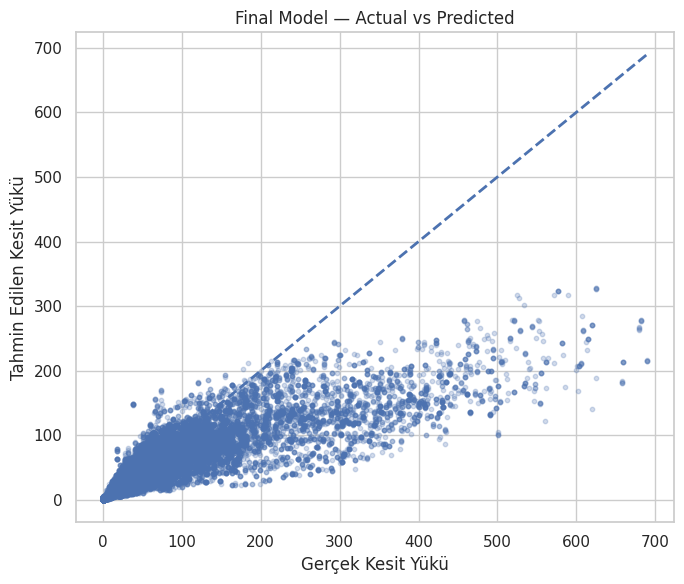

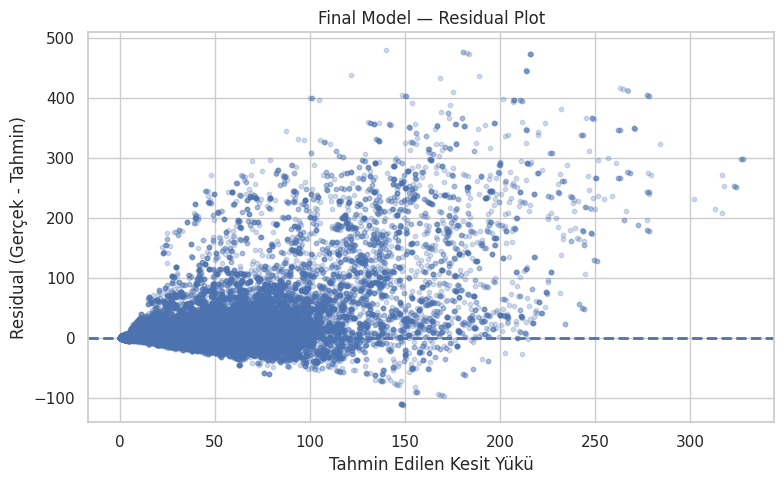

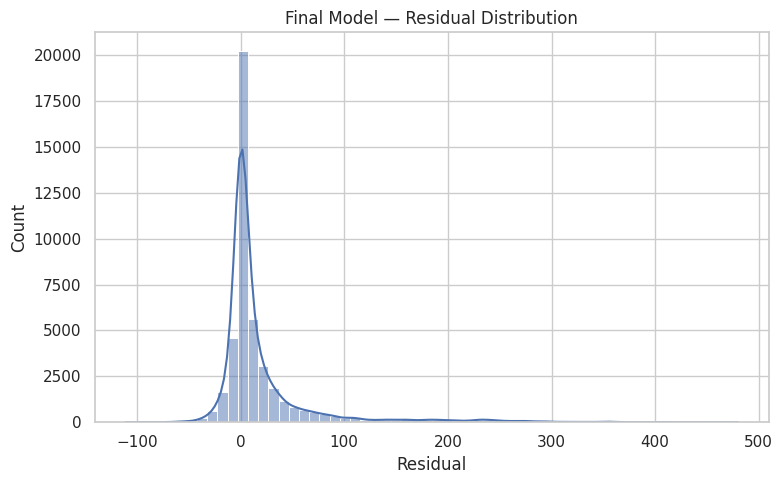

,Date,Line,Direction,Slot_Of_Day,Max_Segment_Load,Predicted_Load,Required_Cars,Recommended_Cars,Capacity_Above_10_Cars
18949,2025-12-01,Blue,0,51,351.208344,145.750000,2,3,False
18950,2025-12-02,Blue,0,51,460.916656,163.820007,3,3,False
18951,2025-12-03,Blue,0,51,426.500000,134.130005,2,3,False
18952,2025-12-04,Blue,0,51,426.250000,192.419998,3,3,False
18953,2025-12-05,Blue,0,51,255.041672,125.279999,2,3,False
18954,2025-12-06,Blue,0,51,58.916668,43.470001,1,3,False
18955,2025-12-07,Blue,0,51,30.750000,29.780001,1,3,False
18956,2025-12-08,Blue,0,51,256.666656,186.110001,3,3,False
18957,2025-12-09,Blue,0,51,465.416656,136.419998,2,3,False
18958,2025-12-10,Blue,0,51,429.916656,151.410004,3,3,False


Oluşturulan dosyalar:
bart_model.json (10,196,790 byte)
model_metadata.json (1,139 byte)
final_test_predictions.csv (2,077,199 byte)
xgboost_tuning_results.csv (2,751 byte)
catboost_tuning_results.csv (1,263 byte)
lightgbm_tuning_results.csv (1,813 byte)
optimized_strong_competitor_comparison.csv (143 byte)


In [8]:
# Train + Validation verisini birleştir. Test setine henüz dokunulmadı.
X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full_log = pd.concat([y_train_log, y_val_log], axis=0)

# Optimize edilmiş XGBoost parametreleriyle final modeli yeniden eğit.
final_model = xgb.XGBRegressor(
    **best_xgb_params,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

final_model.fit(X_train_full, y_train_full_log)

# Bağımsız Aralık test setinde tek final değerlendirme.
test_preds = np.clip(
    np.expm1(final_model.predict(X_test)),
    0,
    None
)

final_metrics = eval_metrics(
    y_test_real,
    test_preds,
    "Final XGBoost (December Test)"
)

print("FINAL TEST METRİKLERİ")
display(pd.DataFrame([final_metrics]))

# 8.1 Actual vs Predicted grafiği
plt.figure(figsize=(7, 6))
plt.scatter(y_test_real, test_preds, alpha=0.25, s=10)
lims = [
    min(float(np.min(y_test_real)), float(np.min(test_preds))),
    max(float(np.max(y_test_real)), float(np.max(test_preds)))
]
plt.plot(lims, lims, "--", linewidth=2)
plt.xlabel("Gerçek Kesit Yükü")
plt.ylabel("Tahmin Edilen Kesit Yükü")
plt.title("Final Model — Actual vs Predicted")
plt.tight_layout()
plt.show()

# 8.2 Residual grafiği
residuals = y_test_real - test_preds

plt.figure(figsize=(8, 5))
plt.scatter(test_preds, residuals, alpha=0.25, s=10)
plt.axhline(0, linestyle="--", linewidth=2)
plt.xlabel("Tahmin Edilen Kesit Yükü")
plt.ylabel("Residual (Gerçek - Tahmin)")
plt.title("Final Model — Residual Plot")
plt.tight_layout()
plt.show()

# 8.3 Residual dağılımı
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=60, kde=True)
plt.xlabel("Residual")
plt.title("Final Model — Residual Distribution")
plt.tight_layout()
plt.show()

# 8.4 Vagon dizilimi fonksiyonu

def recommend_car_consist(
    predicted_10min_load,
    headway_minutes=15,
    target_cap_per_car=110
):
    headway_minutes = max(float(headway_minutes), 1.0)
    target_cap_per_car = max(float(target_cap_per_car), 1.0)

    trains_in_10min = 10.0 / headway_minutes
    passengers_per_train = predicted_10min_load / max(trains_in_10min, 0.25)

    required_cars = int(
        np.ceil(passengers_per_train / target_cap_per_car)
    )
    recommended_cars = int(np.clip(required_cars, 3, 10))

    return required_cars, recommended_cars

# Test sonuç tablosu

test_results = test_df[
    ["Date", "Line", "Direction", "Slot_Of_Day", "Max_Segment_Load"]
].copy()

test_results["Predicted_Load"] = np.round(test_preds, 2)

consist_values = [
    recommend_car_consist(prediction)
    for prediction in test_preds
]

test_results["Required_Cars"] = [item[0] for item in consist_values]
test_results["Recommended_Cars"] = [item[1] for item in consist_values]
test_results["Capacity_Above_10_Cars"] = test_results["Required_Cars"] > 10

display(
    test_results[
        test_results["Slot_Of_Day"] == 51
    ].head(15)
)

test_results.to_csv("final_test_predictions.csv", index=False)

# 8.5 Final modeli Streamlit için JSON formatında kaydet.
final_model.save_model("bart_model.json")

model_metadata = {
    "feature_cols": list(feature_cols),
    "line_mapping": {
        key: int(value)
        for key, value in line_mapping.items()
    },
    "target": "Max_Segment_Load",
    "target_transform": "log1p",
    "training_period": "2025-01-08 to 2025-11-30",
    "test_period": "2025-12-01 to 2025-12-31",
    "lag_definition": {
        "Lag_1d": "Aynı hat, yön ve 10 dakikalık slotun bir gün önceki Max_Segment_Load değeri",
        "Lag_7d": "Aynı hat, yön ve 10 dakikalık slotun yedi gün önceki Max_Segment_Load değeri",
        "Rolling_Mean_7d": "Aynı hat, yön ve 10 dakikalık slotun önceki yedi günlük Max_Segment_Load ortalaması"
    },
    "best_xgb_params": {
        key: value.item() if isinstance(value, np.generic) else value
        for key, value in best_xgb_params.items()
    },
    "random_state": RANDOM_STATE
}

with open("model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(model_metadata, file, ensure_ascii=False, indent=2)

print("Oluşturulan dosyalar:")
for filename in [
    "bart_model.json",
    "model_metadata.json",
    "final_test_predictions.csv",
    "xgboost_tuning_results.csv",
    "catboost_tuning_results.csv",
    "lightgbm_tuning_results.csv",
    "optimized_strong_competitor_comparison.csv"
]:
    if Path(filename).exists():
        print(filename, f"({Path(filename).stat().st_size:,} byte)")

In [9]:
from google.colab import files

files.download("bart_model.json")
files.download("model_metadata.json")
files.download("final_test_predictions.csv")
files.download("optimized_strong_competitor_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>